# Лабораторная работа №1. Обработка изображений

**Студентка:** Мочалова Вероника Андреевна

**Группа:** 3824Б1ПР4

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## 1. Загрузка изображения в оттенках серого

Text(0.5, 1.0, 'Изображение в оттенках серого')

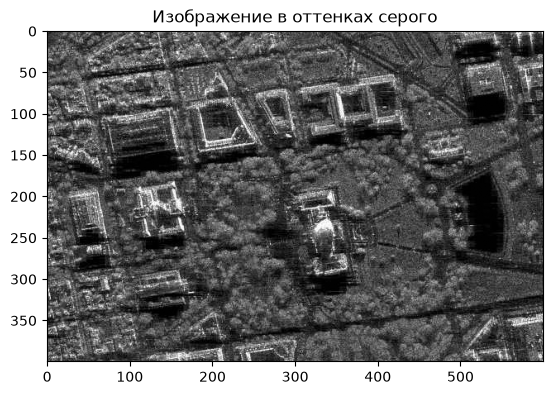

In [11]:
# Загружаем изображение (оно уже серое, но OpenCV прочтет его в 3 канала)
img_color = cv2.imread('sar_1_gray.jpg')

# Конвертируем в серый цвет
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

plt.imshow(img_gray, cmap='gray')
plt.title('Изображение в оттенках серого')

## 2. Построение гистограммы

Используем функцию `cv2.calcHist` для построения гистограммы.

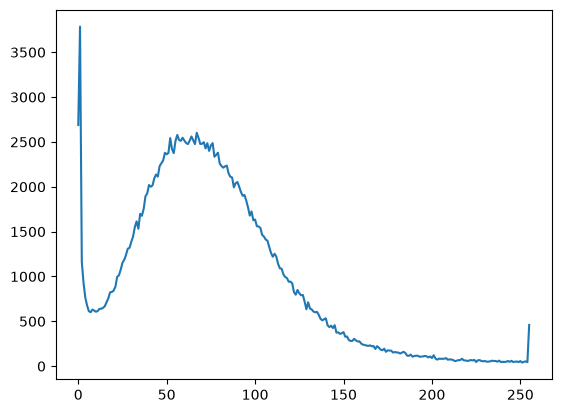

In [12]:
# Задаем параметры для гистограммы
histSize = 256          # Количество корзин (яркостей от 0 до 255)
histRange = (0, 256)    # Диапазон возможных значений яркости
accumulate = False      # Не накапливать гистограмму (сбрасывать перед подсчетом)

# Вычисляем обычную гистограмму
b_hist = cv2.calcHist([img_gray], [0], None, [histSize], histRange, accumulate=accumulate)

# Строим график
plt.plot(b_hist)
plt.show()

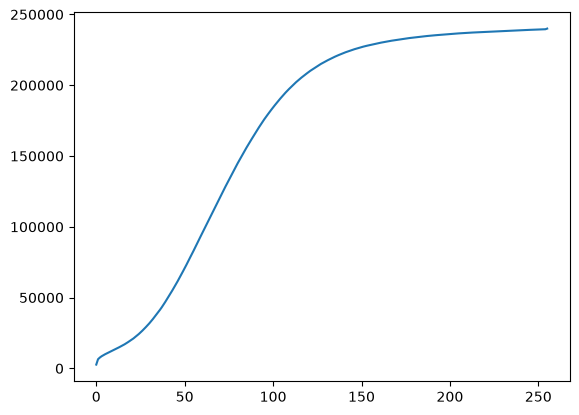

In [13]:
# Считаем кумулятивную (накопленную) сумму
# Она показывает, сколько пикселей имеют яркость меньше или равную текущей
b_hist_cum = b_hist.cumsum()

# Строим график
plt.plot(b_hist_cum)
plt.show()

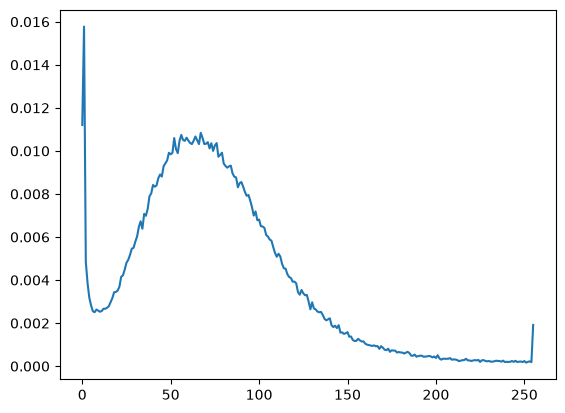

In [14]:
# Нормализуем гистограмму: делим каждое значение на общее количество пикселей
# shape[0] * shape[1] — высота * ширина (общее число пикселей)
b_hist_norm = b_hist / (img_gray.shape[0] * img_gray.shape[1])

# Строим график
plt.plot(b_hist_norm)
plt.show()

## 3. Гамма-коррекция
Реализуем формулу: \(R_{corrected} = (R / 255)^\gamma \times 255\).

При gamma < 1 изображение становится светлее, при gamma > 1 — темнее.

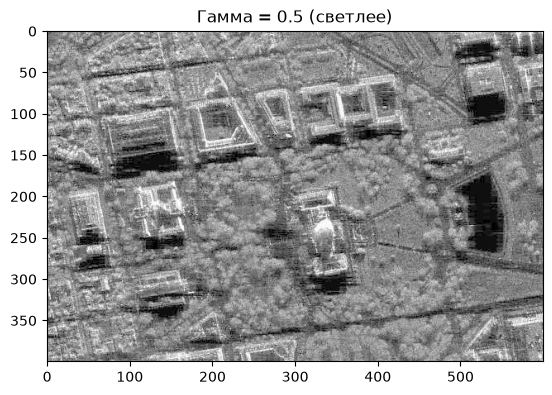

In [22]:
# Высветляем изображение
gamma = 0.5

# Реализация формулы
img_light = (img_gray / 255.0) ** gamma * 255.0
img_light = img_light.astype(np.uint8) # переводим обратно в 8-бит

plt.imshow(img_light, cmap='gray')
plt.title('Гамма = 0.5 (светлее)')
plt.show()

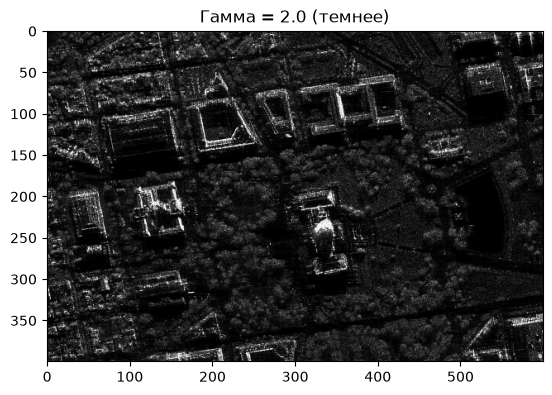

In [23]:
# Затемняем изображение
gamma = 2.0

img_dark = (img_gray / 255.0) ** gamma * 255.0
img_dark = img_dark.astype(np.uint8) # переводим обратно в 8-бит

plt.imshow(img_dark, cmap='gray')
plt.title('Гамма = 2.0 (темнее)')
plt.show()

## 4. Сравнение изображений (MSE, SSIM)

Сравниваем исходное изображение с гамма-скорректированными.

MSE показывает среднеквадратичную ошибку (чем меньше, тем лучше), SSIM — структурное сходство (от 0 до 1).

Гамма=0.5: SSIM = 0.7875, MSE = 3250.43


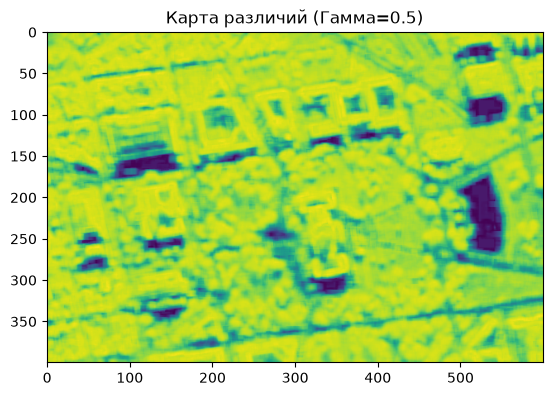

In [24]:
from skimage.metrics import structural_similarity, mean_squared_error

# Считаем SSIM и получаем карту различий
(ssim_light, diff_light) = structural_similarity(img_gray, img_light, full=True)
diff_light = (diff_light * 255).astype("uint8")

# Считаем MSE
mse_light = mean_squared_error(img_gray, img_light)

# Выводим результаты
print(f"Гамма=0.5: SSIM = {ssim_light:.4f}, MSE = {mse_light:.2f}")
plt.imshow(diff_light, cmap='viridis')
plt.title('Карта различий (Гамма=0.5)')
plt.show()

Гамма=2.0: SSIM = 0.5270, MSE = 2383.76


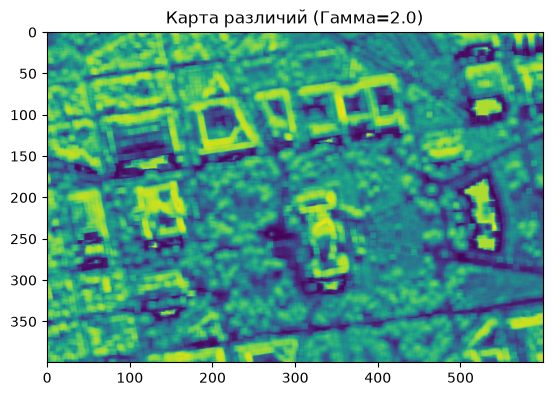

In [25]:
# То же самое для темного изображения
(ssim_dark, diff_dark) = structural_similarity(img_gray, img_dark, full=True)
diff_dark = (diff_dark * 255).astype("uint8")

mse_dark = mean_squared_error(img_gray, img_dark)

print(f"Гамма=2.0: SSIM = {ssim_dark:.4f}, MSE = {mse_dark:.2f}")
plt.imshow(diff_dark, cmap='viridis')
plt.title('Карта различий (Гамма=2.0)')
plt.show()

## 5. Статистическая цветокоррекция на основе eq_gray

Сначала выполним эквализацию гистограммы, а затем применим формулу приведения статистик.

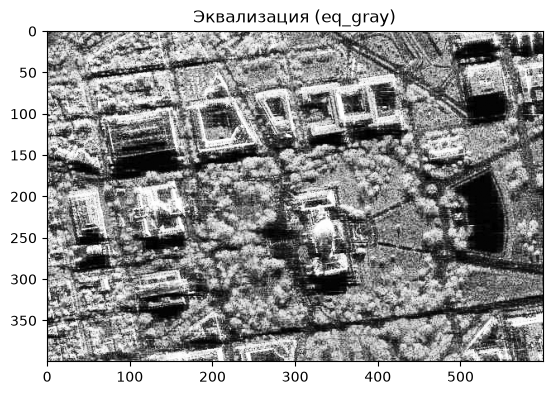

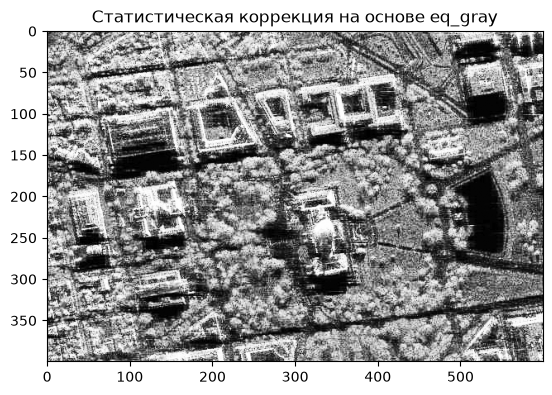

In [29]:
# 1. Делаем эквализацию (выравнивание гистограммы)
eq_gray = cv2.equalizeHist(img_gray)

# Показываем, что получилось после эквализации
plt.imshow(eq_gray, cmap='gray')
plt.title('Эквализация (eq_gray)')
plt.show()

# 2. Применяем статистическую коррекцию к eq_gray
# Считаем текущие E_t (среднее) и D_t (отклонение) для eq_gray
E_t = eq_gray.mean()
D_t = eq_gray.std()

# Задаем целевые E_s (среднее) и D_s (отклонение). 
E_s = 128
D_s = 50

# Формула: C_new = E_s + (C - E_t) * (D_s / D_t)
img_stat = E_s + (eq_gray - E_t) * (D_s / D_t)

# Обрезаем значения и переводим в uint8
img_stat = np.clip(img_stat, 0, 255).astype(np.uint8)

# Показываем финальный результат
plt.imshow(img_stat, cmap='gray')
plt.title('Статистическая коррекция на основе eq_gray')
plt.show()

## 6. Пороговая фильтрация

Тестируем работу алгоритмов с различными параметрами (порогами и типами). Для каждого решения печатаем результат.

Решение: Порог=50, Тип=BINARY. Белых пикселей: 169178


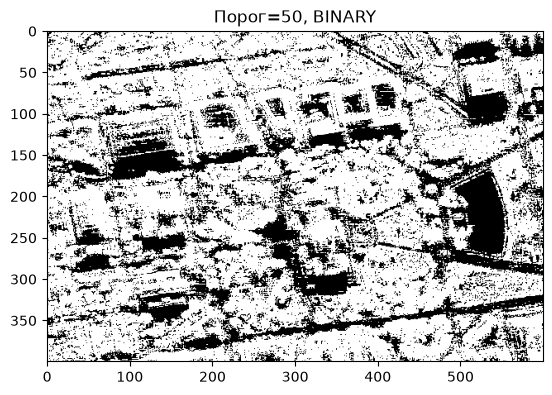

----------------------------------------
Решение: Порог=50, Тип=BINARY_INV. Белых пикселей: 70822


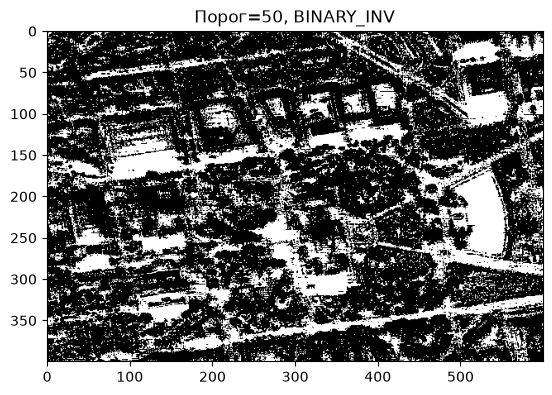

----------------------------------------
Решение: Порог=100, Тип=BINARY. Белых пикселей: 55653


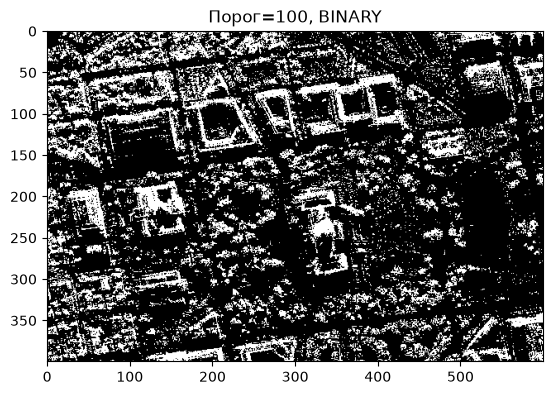

----------------------------------------
Решение: Порог=100, Тип=BINARY_INV. Белых пикселей: 184347


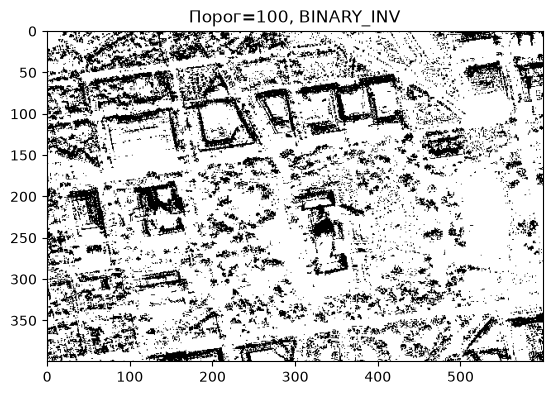

----------------------------------------
Решение: Порог=150, Тип=BINARY. Белых пикселей: 13083


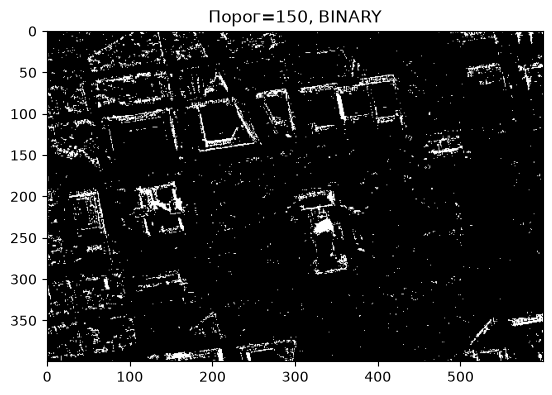

----------------------------------------
Решение: Порог=150, Тип=BINARY_INV. Белых пикселей: 226917


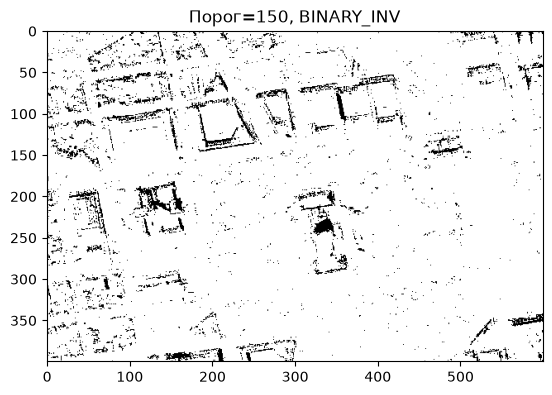

----------------------------------------


In [30]:
# Список порогов для теста
thresholds = [50, 100, 150]

# Берем основные типы пороговой фильтрации для примера
types = [
    (cv2.THRESH_BINARY, 'BINARY'),
    (cv2.THRESH_BINARY_INV, 'BINARY_INV')
]

# Перебираем все комбинации порогов и типов
for t in thresholds:
    for type_val, type_name in types:
        
        # Применяем порог
        _, thresh_img = cv2.threshold(img_gray, t, 255, type_val)
        
        # Считаем, сколько белых пикселей получилось
        white_pixels = np.sum(thresh_img == 255)
        
        # ПЕЧАТАЕМ РЕЗУЛЬТАТ для каждого решения
        print(f"Решение: Порог={t}, Тип={type_name}. Белых пикселей: {white_pixels}")
        
        # Отрисовка фильтраций
        plt.imshow(thresh_img, cmap='gray')
        plt.title(f'Порог={t}, {type_name}')
        plt.show()
        print("-" * 40) # Разделитель для красоты